## 0. Setup Awal

In [3]:
import os
import time
import tracemalloc
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings('ignore')

plt.style.use(
    'seaborn-v0_8-whitegrid'
    if 'seaborn-v0_8-whitegrid' in plt.style.available
    else 'default'
)
plt.rcParams['figure.dpi'] = 120

OUTPUT_DIR = 'outputKNNAntiBurnout'
os.makedirs(OUTPUT_DIR, exist_ok=True)

## 1. Data Understanding

### 1.1 Load Dataset

In [4]:
DATA_PATH = 'burnout_dataset1.csv'
if not os.path.exists(DATA_PATH):
    try:
        from google.colab import files
        print('Silakan upload file burnout_dataset1.csv')
        files.upload()
    except ImportError:
        raise FileNotFoundError(
            f'{DATA_PATH} tidak ditemukan.'
        )

df = pd.read_csv(DATA_PATH)
print(f'Jumlah data awal: {len(df)}')

df = df.sample(
    n=5000,
    random_state=42
).reset_index(drop=True)
print(f'Jumlah data setelah sampling: {len(df)}')

Jumlah data awal: 50000
Jumlah data setelah sampling: 5000


### 1.2 Identifikasi Kolom yang Digunakan

In [5]:
numeric_columns = df.select_dtypes(include='number').columns
categorical_columns = df.select_dtypes(include=['object', 'category']).columns

print('Kolom Numerik:')
print(numeric_columns.tolist())

print('\nKolom Kategorikal:')
print(categorical_columns.tolist())

Kolom Numerik:
['Person_ID', 'Age', 'Monthly_Income_USD', 'Work_Hours_Per_Week', 'Job_Satisfaction', 'Work_Life_Balance', 'Sleep_Hours', 'Anxiety_Score', 'Depression_Score', 'Mood_Score', 'Emotional_Stability', 'Physical_Activity_Hours', 'Meditation_Minutes', 'Screen_Time_Hours', 'Social_Media_Hours', 'Gaming_Hours', 'Coffee_Cups_Per_Day', 'Life_Satisfaction', 'Productivity_Score', 'Absenteeism_Days', 'Burnout_Score']

Kolom Kategorikal:
['Gender', 'Country', 'Occupation', 'Education_Level', 'Employment_Status', 'Remote_Work', 'Sleep_Quality', 'Stress_Level', 'Exercise_Frequency', 'Alcohol_Consumption', 'Smoking', 'Healthy_Diet', 'Chronic_Stress', 'Family_History_Mental_Illness', 'Therapy_Attendance', 'Support_System', 'Mental_Health_Status', 'AI_Wellness_Recommendation', 'Burnout_Risk']


## 2. Preprocessing

### 2.1 Seleksi Kolom

In [6]:
y = df['Burnout_Risk'].copy()

numeric_columns = numeric_columns.drop(
    ['Person_ID', 'Burnout_Score'],
    errors='ignore'
)

categorical_columns = categorical_columns.drop(
    [
        'Gender',
        'Country',
        'Occupation',
        'AI_Wellness_Recommendation',
        'Burnout_Risk',
        'Education_Level',
        'Employment_Status'
    ],
    errors='ignore'
)

selected_columns = list(numeric_columns) + list(categorical_columns)

X = df[selected_columns].copy()
X.head()

,Age,Monthly_Income_USD,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Anxiety_Score,Depression_Score,Mood_Score,Emotional_Stability,...,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Mental_Health_Status
0,19.0,NaN,58,8.0,9.0,9.6,56.0,35.0,54.0,37,...,Moderate,Never,Yes,No,No,No,No,No,Poor,Needs Attention
1,48.0,NaN,53,1.0,8.0,4.7,36.0,NaN,60.0,60,...,Moderate,Never,No,Yes,No,No,Yes,No,Excellent,Needs Attention
2,42.0,NaN,59,3.0,2.0,4.9,44.0,62.0,53.0,49,...,Moderate,Daily,No,Yes,No,No,No,No,Average,Needs Attention
3,22.0,NaN,49,9.0,8.0,6.3,72.0,65.0,29.0,35,...,High,Never,No,Yes,Yes,Yes,No,Yes,Average,Needs Attention
4,62.0,NaN,39,3.0,9.0,4.3,45.0,52.0,69.0,56,...,Moderate,Weekly,No,Yes,No,No,Yes,No,Poor,Needs Attention


### 2.2 Encoding Data Kategorikal

Kolom ordinal dipetakan ke angka; arah skala dibuat konsisten (nilai lebih besar = kondisi lebih berisiko).

In [7]:
encoding_maps = {
    'Remote_Work': {'No': 0, 'Hybrid': 1, 'Yes': 2},
    'Sleep_Quality': {'Excellent': 0, 'Good': 1, 'Average': 2, 'Poor': 3},
    'Stress_Level': {'Low': 0, 'Moderate': 1, 'High': 2},
    'Exercise_Frequency': {'Daily': 0, 'Weekly': 1, 'Rarely': 2, 'Never': 3},
    'Alcohol_Consumption': {'No': 0, 'Yes': 1},
    'Smoking': {'No': 0, 'Yes': 1},
    'Healthy_Diet': {'No': 1, 'Yes': 0},
    'Chronic_Stress': {'No': 0, 'Yes': 1},
    'Family_History_Mental_Illness': {'No': 0, 'Yes': 1},
    'Therapy_Attendance': {'No': 1, 'Yes': 0},
    'Support_System': {'Poor': 3, 'Average': 2, 'Good': 1, 'Excellent': 0},
    'Mental_Health_Status': {'Healthy': 0, 'Needs Attention': 1, 'Critical': 2}
}

for column, mapping in encoding_maps.items():
    X[column] = X[column].map(mapping)

target_mapping = {'Low': 0, 'Moderate': 1, 'High': 2}
y = y.map(target_mapping)

X[categorical_columns].head()

,Remote_Work,Sleep_Quality,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Mental_Health_Status
0,1,0,1,3,1,0,1,0,0,1.0,3,1
1,2,3,1,3,0,1,1,0,1,1.0,0,1
2,0,3,1,0,0,1,1,0,0,1.0,2,1
3,2,2,2,3,0,1,0,1,0,0.0,2,1
4,2,3,1,1,0,1,1,0,1,1.0,3,1


### 2.3 Pemeriksaan Missing Values

In [8]:
missing = X.isnull().sum()
print('Missing value per kolom (hanya yang > 0):')
print(missing[missing > 0])

Missing value per kolom (hanya yang > 0):
Age                          28
Monthly_Income_USD         1450
Job_Satisfaction             37
Work_Life_Balance            60
Sleep_Hours                  85
Anxiety_Score                80
Depression_Score             73
Mood_Score                   91
Physical_Activity_Hours     100
Meditation_Minutes          122
Screen_Time_Hours            84
Social_Media_Hours           62
Gaming_Hours                 69
Life_Satisfaction            75
Productivity_Score           80
Therapy_Attendance           43
dtype: int64


### 2.4 Pembagian Data Latih dan Uji (80:20, stratified)

Data dibagi **sebelum** imputasi dan standardisasi.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print('Dimensi X_train:', X_train.shape)
print('Dimensi X_test :', X_test.shape)

Dimensi X_train: (4000, 31)
Dimensi X_test : (1000, 31)


### 2.5 Penanganan Missing Values dan Standardisasi

KNN berbasis jarak sehingga fitur harus berada pada skala yang sebanding. Nilai hilang diisi dengan rata-rata data latih, lalu fitur distandardisasi.

In [10]:
# Imputasi (rata-rata) dan standardisasi HANYA di-fit pada data latih,
# lalu diterapkan ke data uji agar tidak ada kebocoran informasi (data leakage).
imputer = SimpleImputer(strategy='mean')
scaler = StandardScaler()

X_train_s = pd.DataFrame(
    scaler.fit_transform(imputer.fit_transform(X_train)),
    columns=X.columns,
    index=X_train.index
)

X_test_s = pd.DataFrame(
    scaler.transform(imputer.transform(X_test)),
    columns=X.columns,
    index=X_test.index
)

X_train_s.head()

,Age,Monthly_Income_USD,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Anxiety_Score,Depression_Score,Mood_Score,Emotional_Stability,...,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Mental_Health_Status
4421,-1.629307,1.304873e+00,-0.411320,0.135930,-0.189987,1.265429,0.505992,-0.119761,-0.632388,-0.264124,...,0.383723,-0.469295,1.042398,0.995012,0.975793,-0.404729,1.028918,-0.989197,-1.352329,0.351625
3478,0.883107,-1.408655e+00,-0.479402,-0.908272,0.158264,0.440726,-0.387722,-0.081415,0.112149,0.426245,...,-1.037472,0.414916,1.042398,0.995012,-1.024808,-0.404729,1.028918,-0.989197,0.451377,-0.904177
417,1.672724,3.244300e-16,1.699235,0.832064,0.158264,0.676355,1.788277,1.989246,-1.376925,-1.759924,...,1.804917,0.414916,1.042398,-1.005013,0.975793,2.470788,1.028918,-0.989197,0.451377,1.607426
1691,-0.767908,-1.931955e+00,-0.887897,1.180132,1.203018,-0.560700,-0.620864,-0.618253,0.817499,0.809784,...,-1.037472,1.299126,-0.959326,-1.005013,0.975793,-0.404729,-0.971895,-0.989197,1.353230,-0.904177
3507,-0.552558,-3.987956e-01,0.814163,-0.560205,-0.886490,-0.266163,1.710563,2.065938,-1.729600,-1.529801,...,1.804917,0.414916,-0.959326,0.995012,0.975793,2.470788,-0.971895,1.019587,-1.352329,1.607426


### 2.6 Data Bersih

In [11]:
print('Dimensi data fitur (X)            :', X.shape)
print('Dimensi data latih (X_train_s)    :', X_train_s.shape)
print('Dimensi data uji (X_test_s)       :', X_test_s.shape)
print('Missing value data latih (setelah):', X_train_s.isnull().sum().sum())
print('Missing value data uji (setelah)  :', X_test_s.isnull().sum().sum())
print('\nDistribusi kelas target (y):')
print(y.value_counts().sort_index())

Dimensi data fitur (X)            : (5000, 31)
Dimensi data latih (X_train_s)    : (4000, 31)
Dimensi data uji (X_test_s)       : (1000, 31)
Missing value data latih (setelah): 0
Missing value data uji (setelah)  : 0

Distribusi kelas target (y):
Burnout_Risk
0    2481
1    1512
2    1007
Name: count, dtype: int64


## 3. Modeling

### 3.1 Inisialisasi Model KNN Euclidean

In [12]:
model = KNeighborsClassifier(
    n_neighbors=5,
    metric='euclidean',
    weights='uniform'
)

### 3.2 Eksekusi Model dan Pengukuran Komputasi

Pada KNN proses `fit` hanya menyimpan data latih, sehingga beban komputasi sebenarnya ada pada tahap prediksi. Karena itu waktu prediksi juga diukur.

In [13]:
tracemalloc.start()
start_time = time.process_time()

model.fit(
    X_train_s,
    y_train
)

train_time = time.process_time() - start_time
current, peak = tracemalloc.get_traced_memory()
tracemalloc.stop()

train_memory_mb = peak / (1024 * 1024)

print(f'Waktu Eksekusi Training: {train_time:.4f} detik')
print(f'Penggunaan Memori Peak : {train_memory_mb:.4f} MB')

Waktu Eksekusi Training: 0.0106 detik
Penggunaan Memori Peak : 1.1450 MB


### 3.3 Prediksi Data Uji

In [14]:
start_time = time.process_time()
y_pred = model.predict(X_test_s)
predict_time = time.process_time() - start_time

print(f'Waktu Prediksi Data Uji: {predict_time:.4f} detik')

df_prediksi = pd.DataFrame(
    {
        'Actual': y_test,
        'Predicted': y_pred
    },
    index=X_test_s.index
)

df_prediksi.head()

Waktu Prediksi Data Uji: 0.0864 detik


,Actual,Predicted
761,1,1
4863,0,0
3651,0,0
361,1,1
3197,0,0


## 4. Evaluasi

### 4.1 Laporan Klasifikasi (Classification Report)

In [15]:
target_names = ['Low (0)', 'Moderate (1)', 'High (2)']

report = classification_report(
    y_test,
    y_pred,
    target_names=target_names,
    digits=4
)

print(report)

              precision    recall  f1-score   support

     Low (0)     0.9077    0.9315    0.9194       496
Moderate (1)     0.7178    0.7723    0.7440       303
    High (2)     0.8667    0.7114    0.7814       201

    accuracy                         0.8390      1000
   macro avg     0.8307    0.8051    0.8150      1000
weighted avg     0.8419    0.8390    0.8385      1000



### 4.2 Matriks Kebingungan (Confusion Matrix)

Baris = label aktual, kolom = label prediksi.

In [16]:
cm = confusion_matrix(
    y_test,
    y_pred
)

pd.DataFrame(
    cm,
    index=[f'Aktual {n}' for n in target_names],
    columns=[f'Prediksi {n}' for n in target_names]
)

,Prediksi Low (0),Prediksi Moderate (1),Prediksi High (2)
Aktual Low (0),462,34,0
Aktual Moderate (1),47,234,22
Aktual High (2),0,58,143


### 4.3 Metrik Evaluasi Data Uji

Precision, recall, dan F1-score pada klasifikasi 3 kelas dirata-ratakan dengan **macro** (rata-rata sederhana antar kelas) dan **weighted** (dibobot jumlah data tiap kelas).

In [17]:
acc = accuracy_score(y_test, y_pred)

prec_macro = precision_score(y_test, y_pred, average='macro')
rec_macro = recall_score(y_test, y_pred, average='macro')
f1_macro = f1_score(y_test, y_pred, average='macro')

prec_weighted = precision_score(y_test, y_pred, average='weighted')
rec_weighted = recall_score(y_test, y_pred, average='weighted')
f1_weighted = f1_score(y_test, y_pred, average='weighted')

print(f'Accuracy            : {acc:.4f}')
print(f'Precision (Macro)   : {prec_macro:.4f}')
print(f'Recall (Macro)      : {rec_macro:.4f}')
print(f'F1-Score (Macro)    : {f1_macro:.4f}')
print(f'Precision (Weighted): {prec_weighted:.4f}')
print(f'Recall (Weighted)   : {rec_weighted:.4f}')
print(f'F1-Score (Weighted) : {f1_weighted:.4f}')

Accuracy            : 0.8390
Precision (Macro)   : 0.8307
Recall (Macro)      : 0.8051
F1-Score (Macro)    : 0.8150
Precision (Weighted): 0.8419
Recall (Weighted)   : 0.8390
F1-Score (Weighted) : 0.8385


### 4.4 Evaluasi Stratified 5-Fold Cross-Validation

Imputasi dan standardisasi dimasukkan ke dalam `Pipeline` sehingga pada setiap fold keduanya hanya di-fit pada data latih fold tersebut.

In [18]:
cv_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=5, metric='euclidean', weights='uniform'))
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scoring = {
    'accuracy': 'accuracy',
    'precision_macro': 'precision_macro',
    'recall_macro': 'recall_macro',
    'f1_macro': 'f1_macro',
    'f1_weighted': 'f1_weighted'
}

cv_results = cross_validate(
    cv_pipeline,
    X,
    y,
    cv=cv,
    scoring=cv_scoring
)

df_cv = pd.DataFrame(
    {
        'Fold': [f'Fold {i+1}' for i in range(5)],
        'Accuracy': cv_results['test_accuracy'],
        'Precision (Macro)': cv_results['test_precision_macro'],
        'Recall (Macro)': cv_results['test_recall_macro'],
        'F1-Score (Macro)': cv_results['test_f1_macro'],
        'F1-Score (Weighted)': cv_results['test_f1_weighted']
    }
)

df_cv.loc['Mean'] = df_cv.mean(numeric_only=True)
df_cv.loc['Std'] = df_cv.std(numeric_only=True)
df_cv

,Fold,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),F1-Score (Weighted)
0,Fold 1,0.842000,0.841076,0.816844,0.825637,0.843136
1,Fold 2,0.836000,0.827304,0.808791,0.816569,0.836000
2,Fold 3,0.849000,0.840378,0.814707,0.824650,0.848265
3,Fold 4,0.851000,0.847068,0.824942,0.833154,0.851791
4,Fold 5,0.856000,0.853794,0.838986,0.844185,0.857742
Mean,NaN,0.846800,0.841924,0.820854,0.828839,0.847387
Std,NaN,0.007026,0.008766,0.010439,0.009300,0.007418


### 4.5 Ringkasan Waktu Eksekusi dan Penggunaan Memori

In [19]:
df_runtime = pd.DataFrame(
    [
        {
            'Model': 'KNN Euclidean',
            'Training_Time_Seconds': round(train_time, 4),
            'Prediction_Time_Seconds': round(predict_time, 4),
            'Peak_Memory_MB': round(train_memory_mb, 4)
        }
    ]
)

df_runtime

,Model,Training_Time_Seconds,Prediction_Time_Seconds,Peak_Memory_MB
0,KNN Euclidean,0.0106,0.0864,1.145


### 4.6 Ringkasan Evaluasi Model

In [20]:
evaluation_result = pd.DataFrame(
    {
        'Model': ['KNN Euclidean'],
        'Distance_Metric': ['Euclidean'],
        'K_Neighbors': [5],
        'Weights': ['uniform'],
        'Accuracy': [round(acc, 4)],
        'Precision_Macro': [round(prec_macro, 4)],
        'Recall_Macro': [round(rec_macro, 4)],
        'F1_Score_Macro': [round(f1_macro, 4)],
        'Precision_Weighted': [round(prec_weighted, 4)],
        'Recall_Weighted': [round(rec_weighted, 4)],
        'F1_Score_Weighted': [round(f1_weighted, 4)],
        'CV_5Fold_Accuracy_Mean': [round(cv_results['test_accuracy'].mean(), 4)],
        'CV_5Fold_F1_Macro_Mean': [round(cv_results['test_f1_macro'].mean(), 4)],
        'Training_Time_s': [round(train_time, 4)],
        'Prediction_Time_s': [round(predict_time, 4)],
        'Peak_Memory_MB': [round(train_memory_mb, 4)]
    }
)

evaluation_result

,Model,Distance_Metric,K_Neighbors,Weights,Accuracy,Precision_Macro,Recall_Macro,F1_Score_Macro,Precision_Weighted,Recall_Weighted,F1_Score_Weighted,CV_5Fold_Accuracy_Mean,CV_5Fold_F1_Macro_Mean,Training_Time_s,Prediction_Time_s,Peak_Memory_MB
0,KNN Euclidean,Euclidean,5,uniform,0.839,0.8307,0.8051,0.815,0.8419,0.839,0.8385,0.8468,0.8288,0.0106,0.0864,1.145


## 5. Visualisasi Hasil

### 5.1 Confusion Matrix Heatmap

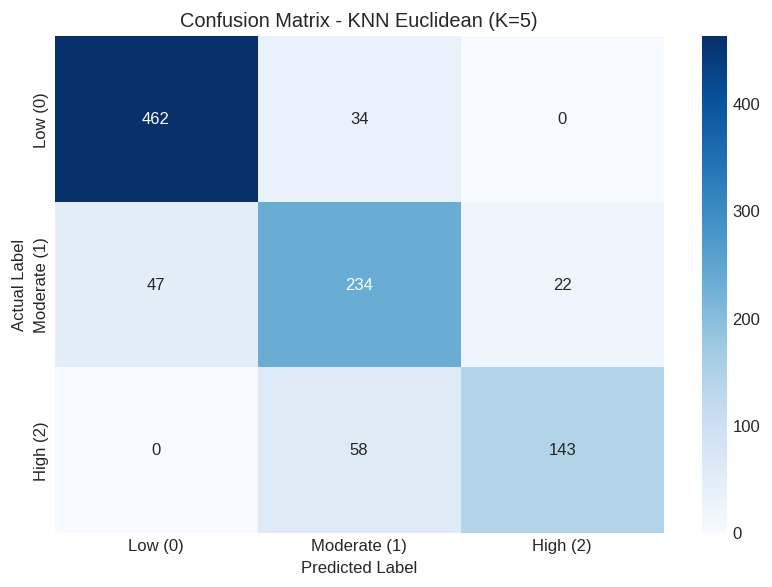

In [21]:
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=target_names,
    yticklabels=target_names
)
plt.title('Confusion Matrix - KNN Euclidean (K=5)')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/confusion_matrix_euclidean.png')
plt.show()

### 5.2 Distribusi Kelas Aktual vs Prediksi

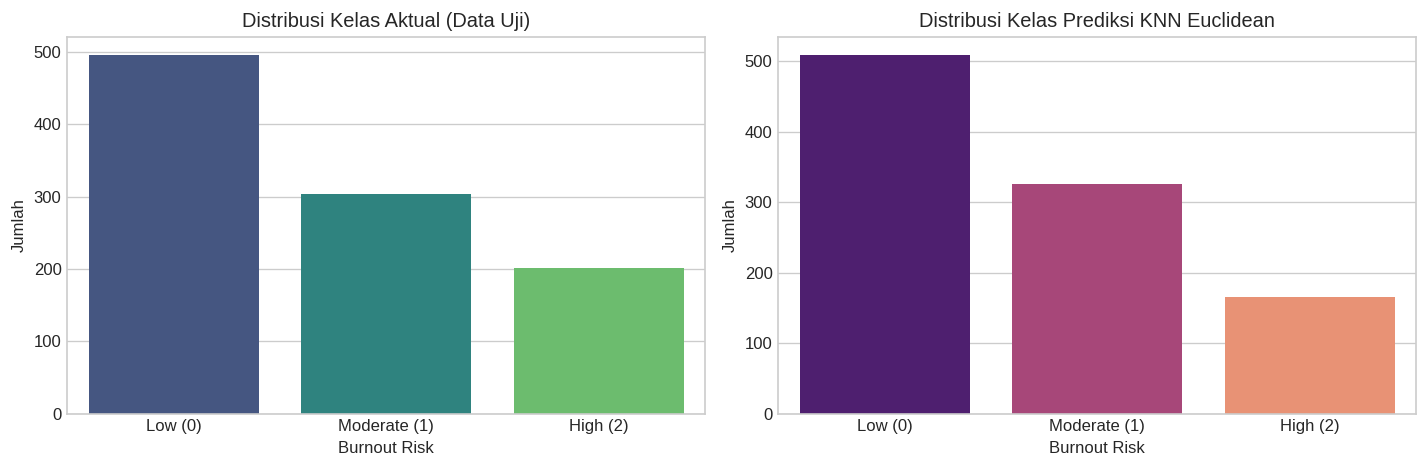

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(x=y_test, ax=axes[0], palette='viridis')
axes[0].set_title('Distribusi Kelas Aktual (Data Uji)')
axes[0].set_xticks([0, 1, 2])
axes[0].set_xticklabels(target_names)
axes[0].set_xlabel('Burnout Risk')
axes[0].set_ylabel('Jumlah')

sns.countplot(x=pd.Series(y_pred), ax=axes[1], palette='magma')
axes[1].set_title('Distribusi Kelas Prediksi KNN Euclidean')
axes[1].set_xticks([0, 1, 2])
axes[1].set_xticklabels(target_names)
axes[1].set_xlabel('Burnout Risk')
axes[1].set_ylabel('Jumlah')

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/distribution_actual_vs_predicted_euclidean.png')
plt.show()

### 5.3 Metrik Stratified 5-Fold Cross-Validation

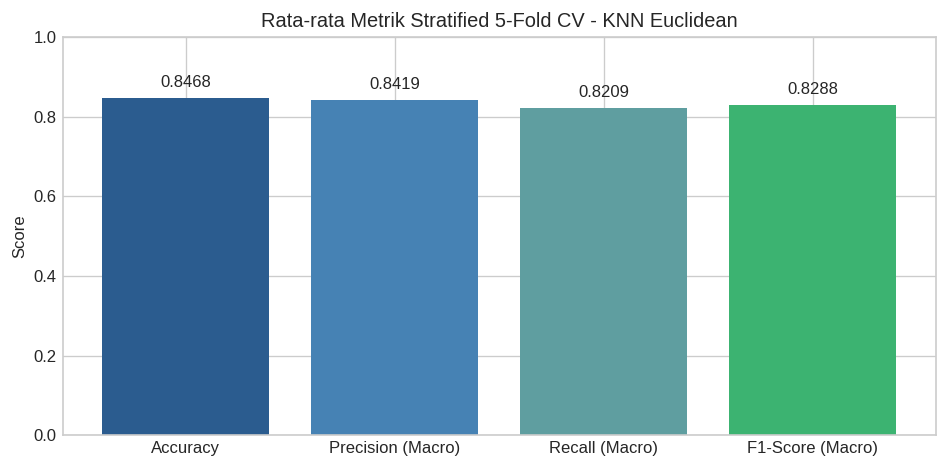

In [23]:
metrics_cv = ['Accuracy', 'Precision (Macro)', 'Recall (Macro)', 'F1-Score (Macro)']
cv_means = [
    cv_results['test_accuracy'].mean(),
    cv_results['test_precision_macro'].mean(),
    cv_results['test_recall_macro'].mean(),
    cv_results['test_f1_macro'].mean()
]

plt.figure(figsize=(8, 4))
bars = plt.bar(
    metrics_cv,
    cv_means,
    color=['#2b5c8f', '#4682b4', '#5f9ea0', '#3cb371']
)
plt.title('Rata-rata Metrik Stratified 5-Fold CV - KNN Euclidean')
plt.ylabel('Score')
plt.ylim(0, 1)

for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        yval + 0.02,
        f'{yval:.4f}',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/cv_metrics_euclidean.png')
plt.show()

## 6. Analisis

### 6.1 Sensitivitas Nilai K

Model dilatih ulang dengan beberapa nilai K untuk melihat pengaruhnya terhadap akurasi latih, akurasi uji, dan error rate.

In [24]:
k_range = [1, 3, 5, 7, 9, 11, 15, 21, 25]
train_scores = []
test_scores = []
error_rates = []

for k in k_range:
    knn_temp = KNeighborsClassifier(
        n_neighbors=k,
        metric='euclidean',
        weights='uniform'
    )
    knn_temp.fit(X_train_s, y_train)
    train_acc = knn_temp.score(X_train_s, y_train)
    test_acc = knn_temp.score(X_test_s, y_test)
    train_scores.append(train_acc)
    test_scores.append(test_acc)
    error_rates.append(1 - test_acc)

df_k_analysis = pd.DataFrame(
    {
        'K': k_range,
        'Train_Accuracy': [round(v, 4) for v in train_scores],
        'Test_Accuracy': [round(v, 4) for v in test_scores],
        'Error_Rate': [round(v, 4) for v in error_rates]
    }
)

df_k_analysis

,K,Train_Accuracy,Test_Accuracy,Error_Rate
0,1,1.0000,0.794,0.206
1,3,0.9223,0.833,0.167
2,5,0.9042,0.839,0.161
3,7,0.8972,0.853,0.147
4,9,0.8920,0.860,0.140
5,11,0.8888,0.854,0.146
6,15,0.8820,0.856,0.144
7,21,0.8728,0.860,0.140
8,25,0.8735,0.854,0.146


### 6.2 Visualisasi Akurasi dan Error Rate terhadap Nilai K

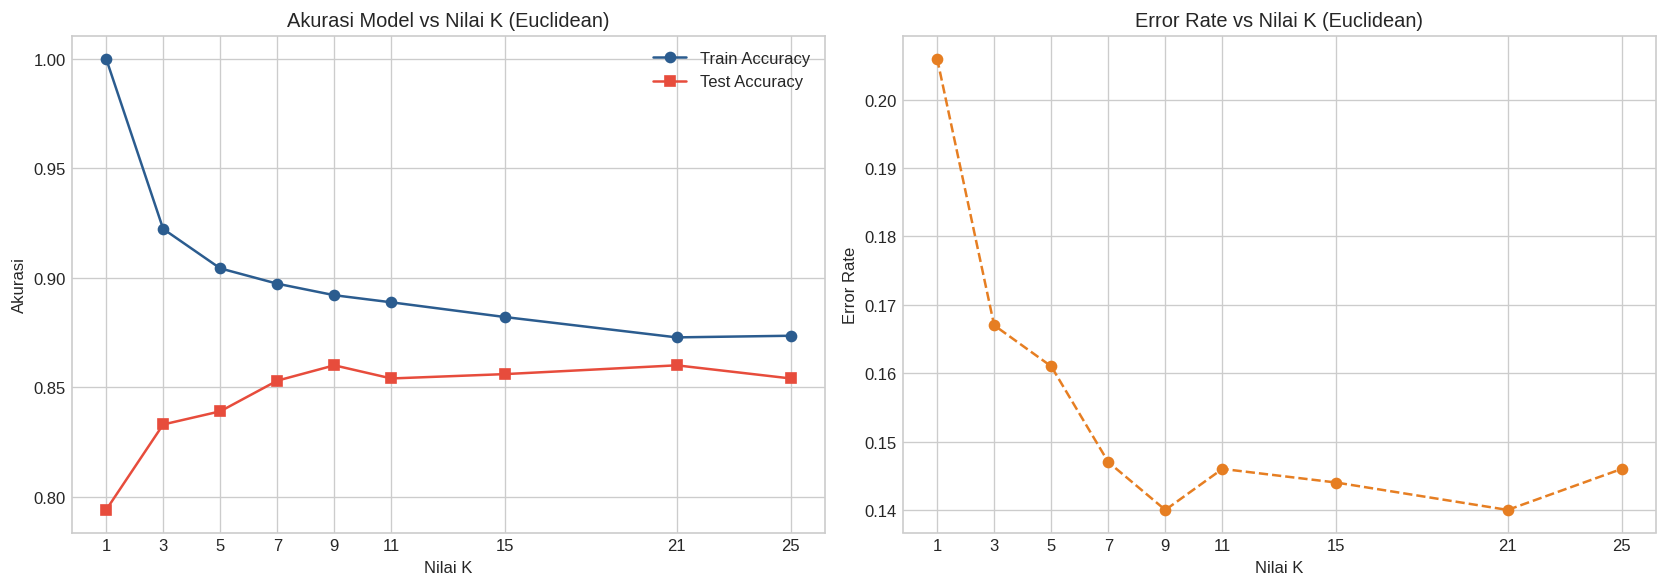

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_range, train_scores, marker='o', label='Train Accuracy', color='#2b5c8f')
axes[0].plot(k_range, test_scores, marker='s', label='Test Accuracy', color='#e74c3c')
axes[0].set_title('Akurasi Model vs Nilai K (Euclidean)')
axes[0].set_xlabel('Nilai K')
axes[0].set_ylabel('Akurasi')
axes[0].set_xticks(k_range)
axes[0].legend()

axes[1].plot(k_range, error_rates, marker='o', linestyle='--', color='#e67e22')
axes[1].set_title('Error Rate vs Nilai K (Euclidean)')
axes[1].set_xlabel('Nilai K')
axes[1].set_ylabel('Error Rate')
axes[1].set_xticks(k_range)

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/k_value_sensitivity_euclidean.png')
plt.show()

## 7. Ekspor File


In [26]:
evaluation_result.to_csv(f'{OUTPUT_DIR}/metrics_knn_euclidean.csv', index=False)
df_prediksi.to_csv(f'{OUTPUT_DIR}/predictions_knn_euclidean.csv')
df_cv.to_csv(f'{OUTPUT_DIR}/cv_5fold_knn_euclidean.csv')
df_k_analysis.to_csv(f'{OUTPUT_DIR}/k_analysis_knn_euclidean.csv', index=False)

for name in sorted(os.listdir(OUTPUT_DIR)):
    print('-', name)

- confusion_matrix_euclidean.png
- cv_5fold_knn_euclidean.csv
- cv_metrics_euclidean.png
- distribution_actual_vs_predicted_euclidean.png
- k_analysis_knn_euclidean.csv
- k_value_sensitivity_euclidean.png
- metrics_knn_euclidean.csv
- predictions_knn_euclidean.csv
